In [151]:
# Install required libraries

!pip install typing_extensions --upgrade
!pip install --upgrade opencv-python
!pip install --upgrade opencv-contrib-python
!pip install --upgrade scikit-image
!pip install -U albumentations
!pip install --upgrade scikit-learn
# Import necessary libraries
import tensorflow as tf
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [435]:
import matplotlib.pyplot as plt
import glob
from itertools import chain
from PIL import Image,ImageOps
from albumentations import ColorJitter

scal=2.5
def resizeImg(img):
    return img.resize((int(img.width // scal), int(img.height // scal)))

input_shape=(int(360//scal),int(424//scal),3)
# Create an instance of ImageDataGenerator with basic augmentations
datagen = ImageDataGenerator(
    rotation_range=7,
    width_shift_range=0.25,
    height_shift_range=0.10,
    shear_range=0.5,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
pref_path='./'
img_paths = chain(glob.iglob('[0-9]*mod.png'),glob.iglob('mod[0-9]*.png'))

limit=400
clnToNois=2/3.0
basAugFact=1.3
possmp=np.empty((0,)+input_shape)
negsmp=np.empty((0,)+input_shape)
#modify images slightly to create more images
for path in img_paths:
    possmp=np.append(possmp,np.expand_dims(img_to_array(resizeImg(load_img(path))).astype('float32') / 255.0,axis=0),axis=0)
    possmp=np.append(possmp,np.expand_dims(ColorJitter(brightness=(0.3),contrast=(0.2),
        saturation=(0.2),hue=(0.3), p=1.0)(image=img_to_array(resizeImg(load_img(path))).astype(
        'float32') / 255.0)['image'],axis=0),axis=0)
    possmp=np.append(possmp,np.expand_dims(ColorJitter(brightness=(0.2),contrast=(0.3),
        saturation=(0.25),hue=(0.2))(image=img_to_array(resizeImg(load_img(path))).astype('float32') / 255.0)['image'],axis=0),axis=0)
clnposend=len(possmp)

for batch in datagen.flow(possmp[:clnposend], batch_size=1):
    possmp=np.append(possmp, np.expand_dims(batch[0],axis=0),axis=0)
    if (len(possmp) >= int(limit*clnToNois/basAugFact)):
        break
    
datagen = ImageDataGenerator(
    rotation_range=5,
    width_shift_range=0.1,
    height_shift_range=0.15,
    shear_range=0.3,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)
for batch in datagen.flow(possmp[:clnposend], batch_size=10):   
    possmp=np.append(possmp, np.expand_dims(batch[0],axis=0),axis=0)
    if (len(possmp) >= int(limit*clnToNois)):
        break
        
for file in glob.iglob('falsneg[0-9]*.png'):
    possmp=np.append(possmp,np.expand_dims(img_to_array(resizeImg(load_img(file))).astype('float32') / 255.0,axis=0),axis=0)
    possmp=np.append(possmp,np.expand_dims(ColorJitter(brightness=0.2,contrast=0.3,
        saturation=0.125,hue=0.1)(image=img_to_array(resizeImg(load_img(file))).astype(
        'float32')/255.0)['image'],axis=0),axis=0)

    
for path in glob.iglob('[0-1][0-9]clip[0-9]*.png'):
    negsmp=np.append(negsmp,np.expand_dims(img_to_array(resizeImg(load_img(path))).astype('float32') / 255.0,axis=0),axis=0)
    negsmp=np.append(negsmp,np.expand_dims(img_to_array(resizeImg(ImageOps.invert(load_img(path)))).astype('float32')/255.0,axis=0),axis=0)
    negsmp=np.append(negsmp,np.moveaxis(np.stack((img_to_array(resizeImg(load_img(path).convert("L"))),) * 3, axis=-1),-2,0).astype('float32')/255.0,axis=0)
clnnegend=len(negsmp)

for file in glob.iglob('falspos[0-9]*.png'):
    negsmp=np.append(negsmp, np.expand_dims(ColorJitter(brightness=0.3,contrast=0.4,
        saturation=0.4,hue=0.3)(image=img_to_array(resizeImg(ImageOps.invert(load_img(file)))).astype(
        'float32')/255.0)['image'],axis=0),axis=0)

datagen = ImageDataGenerator(
    rotation_range=38,
    width_shift_range=0.7,
    height_shift_range=0.6,
    shear_range=0.5,
    zoom_range=0.8,
    vertical_flip=True,
    horizontal_flip=True,
    fill_mode='nearest'
)
i=1
for batch in datagen.flow(negsmp[0:clnnegend], batch_size=1):   
    negsmp=np.append(negsmp, np.expand_dims(batch[0],axis=0),axis=0)
    if (len(negsmp) == limit or i % 20 == 0):
        break
    i += 1


In [436]:
# Create an instance of ImageDataGenerator with normalization options
datagen = ImageDataGenerator(featurewise_center=True,featurewise_std_normalization=True,
    samplewise_center=False,samplewise_std_normalization=False)

   # Generate batches of normalized images of already negative classified images
datagen.fit(negsmp[0:clnnegend],rounds=15)
i = 0
for batch in datagen.flow(negsmp[0:clnnegend],batch_size=1):
    negsmp=np.append(negsmp,np.expand_dims(batch[0],axis=0),axis=0)
    i += 1
    if (len(negsmp)== limit or i % 30 == 0):
        break

datagen = ImageDataGenerator(
    featurewise_center=True,
    featurewise_std_normalization=True,
    samplewise_center=True,
    samplewise_std_normalization=True
)
datagen.fit(negsmp[0:clnnegend],rounds=15)
i = 0
for batch in datagen.flow(negsmp[0:clnnegend],batch_size=1):
    negsmp=np.append(negsmp, np.expand_dims(batch[0],axis=0),axis=0)
    i += 1
    if (len(negsmp)==limit or i % 25 == 0):
        break


In [437]:

# Define a custom data augmentation function
def add_random_noise(image):
    noise = np.random.normal(0.05, 0.05, image.shape)
    return image + noise

# Create an instance of ImageDataGenerator with the custom augmentation
datagen = ImageDataGenerator(preprocessing_function=add_random_noise)

# Generate batches of augmented images with minimum noise
for batch in datagen.flow(possmp[:clnposend], batch_size=5):
    possmp=np.append(possmp,np.expand_dims(batch[0],axis=0),axis=0)
    if (len(possmp)>=limit):
        break

        
# rotate imanges 90 degrees
i=0
for batch in possmp[:clnposend]:
    negsmp=np.append(negsmp,np.expand_dims(cv2.warpAffine(batch,\
            cv2.getRotationMatrix2D((batch.shape[1] // 2,\
            batch.shape[0] // 2), 90, 1.0),(batch.shape[1],batch.shape[0])),axis=0),axis=0)
    i=i+1
    if (len(negsmp)==limit or i % 25 == 0):
        break
        
def add_random_noise2(image):
    noise = np.random.normal(0.8, 1, image.shape)
    return image + noise
datagen = ImageDataGenerator(
    rotation_range=45,
    width_shift_range=0.1,
    height_shift_range=0.6,
    shear_range=0.5,
    zoom_range=0.8,
    vertical_flip=True,
    horizontal_flip=False,
    fill_mode='wrap',
    preprocessing_function=add_random_noise2
)
#add noise-shift to create even more negative images
for batch in datagen.flow(possmp[:clnposend], batch_size=1):
    negsmp=np.append(negsmp,np.expand_dims(batch[0],axis=0),axis=0)
    if (len(negsmp)>= limit):
        break


y=np.ones((limit*2,))
y[limit:]=0
rng = np.random.default_rng()
negsmp=rng.permutation(negsmp)[:limit]
possmp=rng.permutation(possmp)[:limit]

In [438]:
import cv2
from skimage.feature import graycomatrix, graycoprops,hog
def get_features_rfc(img):
    if img.max() <= 1.0:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)
    glcm=graycomatrix(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), distances=[1], angles=[0],levels=256, symmetric=True, normed=True)
    res= np.append(hog(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY),orientations=10,pixels_per_cell=(2,2),cells_per_block=(2,2),visualize=False,feature_vector=True),
    np.array([graycoprops(glcm, 'contrast')[0,0],graycoprops(glcm, 'correlation')[0, 0],graycoprops(glcm, 'energy')[0, 0],
                                       graycoprops(glcm, 'homogeneity')[0, 0]]),axis=0)
    res[~np.isfinite(res)] = np.finfo(np.float32).max
    return res

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


positive samples


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

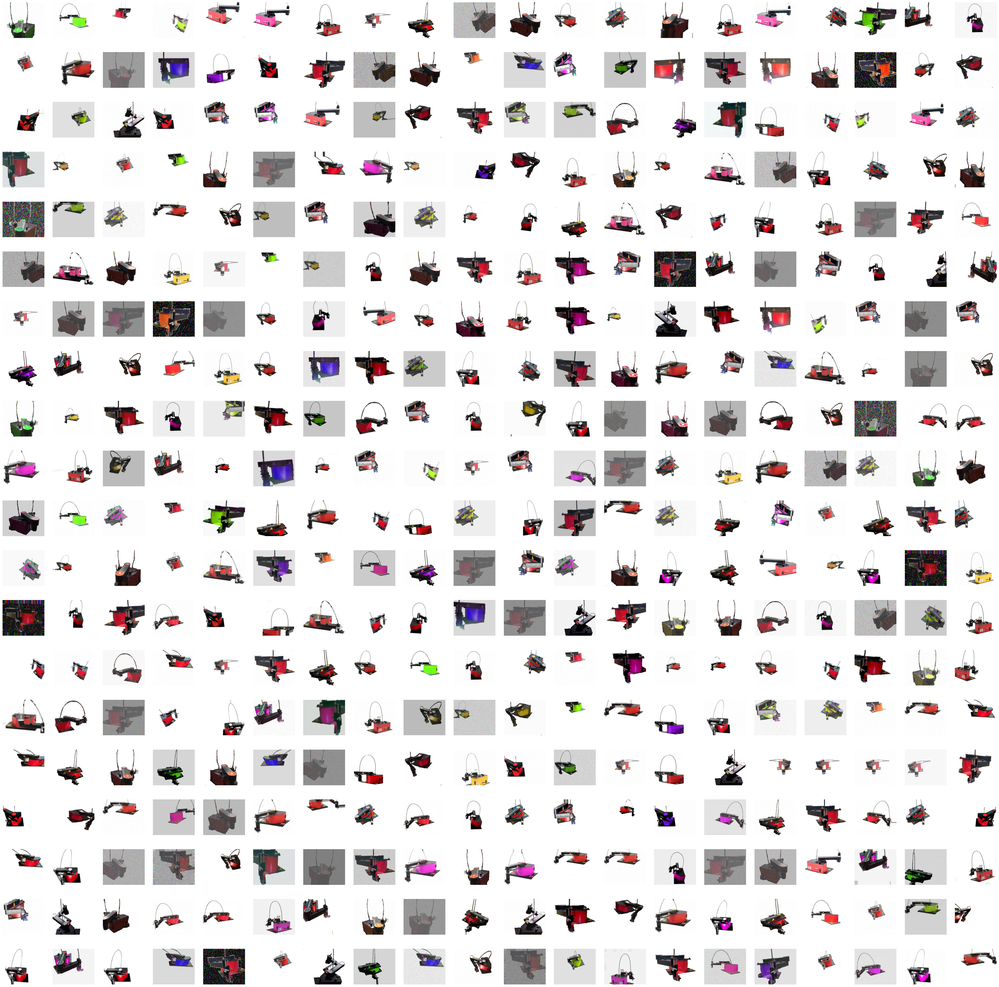

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


negative samples


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

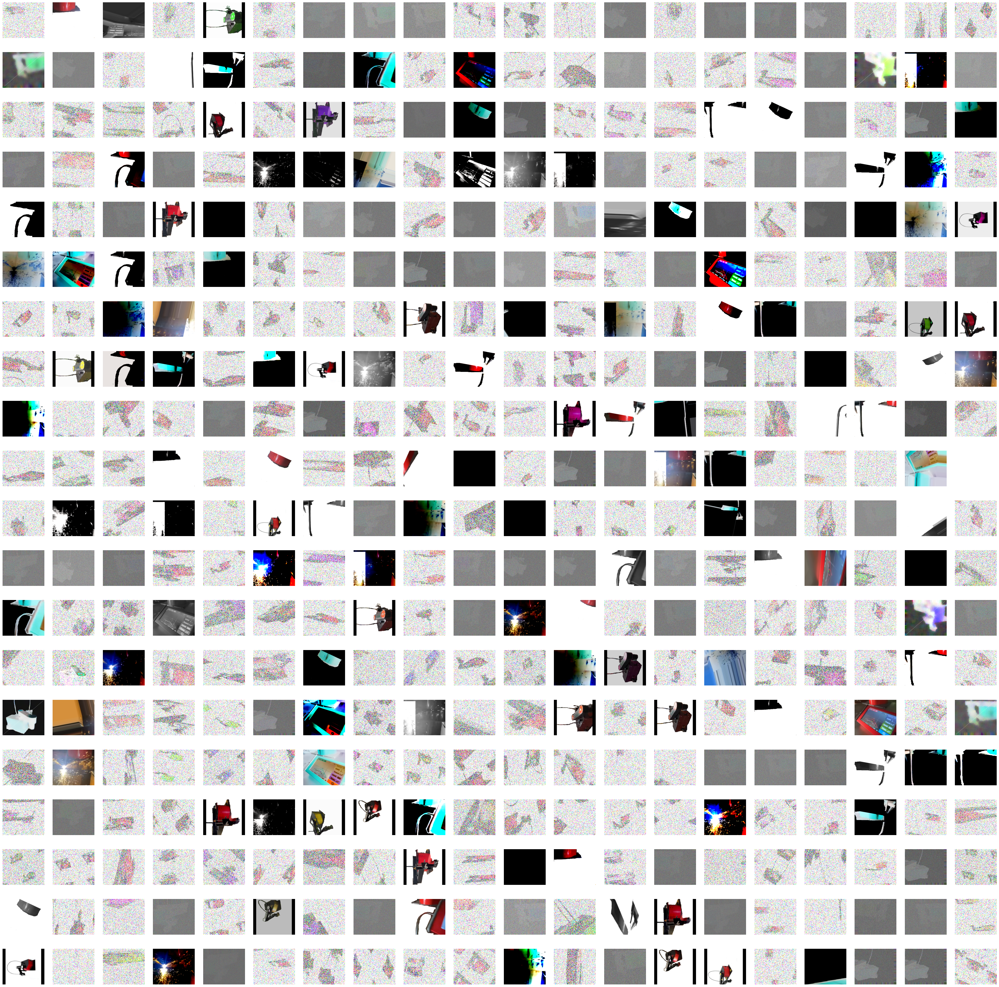

In [439]:
print("positive samples")
plt.figure(figsize=(50, 50))
for i in range(len(possmp)):
    plt.subplot(20, 20, i+1)
    plt.imshow(possmp[i])
    plt.axis('off')
plt.show()
print("negative samples")
plt.figure(figsize=(50, 50))
for i in range(len(negsmp)):
    plt.subplot(20, 20, i+1)
    plt.imshow(negsmp[i])
    plt.axis('off')
plt.show()

In [440]:
# Compute features
y_train=np.ones((limit*2,))
y_train[limit:]=0
x_train=np.zeros((0,235724,))

for img in np.append(possmp,negsmp,axis=0):
    x_train=np.concatenate((x_train,np.expand_dims(get_features_rfc(img),axis=0)),axis=0)

In [441]:
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
rfc_model=RandomForestClassifier(random_state=40)
rf_grid=RandomizedSearchCV(estimator = rfc_model, param_distributions = {
'n_estimators':  [int(x) for x in np.linspace(start = 5, stop = 500, num = 50)],
'max_features': ['sqrt','log2'],'max_depth': [5,10,15,25],'min_samples_split': [5,10, 12],
#number of parallel tasks set to 8
'min_samples_leaf': [5,10,15]}, cv=2, n_iter=300,n_jobs=8)
x_train1, x_test, y_train1, y_test = train_test_split(x_train, y_train, test_size=0.3, random_state=32)
#this takes 20-30 min to run
rf_grid.fit(x_train1,y_train1)
# first two should be 1-last should be zero
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'01mod.png')))),axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'poscand.png')))),axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'poscand1.png')))),axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'poscand2.png')))),axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'negcand.png')))),axis=0)))

print(rf_grid.score(x_test,y_test))
print(rf_grid.best_params_)
# get first 200000 of most important features
imp_idxs=np.argsort(rf_grid.best_estimator_.feature_importances_)[-200000:][::-1]

[1.]
[1.]
[1.]
[1.]
[1.]
0.8208333333333333
{'n_estimators': 45, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 5}


In [442]:
rfc_model=RandomForestClassifier(random_state=35)
rf_grid=RandomizedSearchCV(estimator = rfc_model, param_distributions = {
'n_estimators':  [int(x) for x in np.linspace(start = 5, stop = 500, num = 50)],
'max_features': ['sqrt','log2'],'max_depth': [5,10,15,25],'min_samples_split': [5,10,15],
'min_samples_leaf': [5,10, 15]}, cv=2, n_iter=500,n_jobs=8)
x_train1, x_test, y_train1, y_test = train_test_split(x_train[0:,imp_idxs], y_train, test_size=0.3, random_state=32)
rf_grid.fit(x_train1,y_train1)

print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'poscand1.png'))))[imp_idxs],axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'poscand2.png'))))[imp_idxs],axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'negcand.png'))))[imp_idxs],axis=0)))
print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'falspos0.png'))))[imp_idxs],axis=0)))

print(rf_grid.score(x_test,y_test))
print(rf_grid.best_params_)
del x_train1,y_train1

[1.]
[1.]
[1.]
[0.]
0.8541666666666666
{'n_estimators': 15, 'min_samples_split': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 25}


In [443]:
x_train, x_test, y_train, y_test = train_test_split(
    np.append(possmp,negsmp,axis=0), y, test_size=0.3, random_state=42
)
# back up test data so can run model again on same dataset for model tuning
x_testbak=x_test
y_testbak=y_test

In [444]:
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D
from tensorflow.keras.layers import LeakyReLU,PReLU
from sklearn.model_selection import train_test_split
from os import path

rng = np.random.default_rng()
negsmp=rng.permutation(negsmp)[:limit]
possmp=rng.permutation(possmp)[:limit]

#use custom class to check if reached validation loss limit
class StopAtLossValue(tf.keras.callbacks.Callback):
    def __init__(self, target_loss):
        super(StopAtLossValue, self).__init__()
        self.target_loss = target_loss

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        # Use 'loss' for training loss, or 'val_loss' for validation loss
        current_loss = logs.get('val_loss')

        if current_loss is not None and current_loss <= self.target_loss:
            print(f'\n\nEpoch {epoch + 1}: Reached target loss of {self.target_loss}, stopping training!')
            self.model.stop_training = True

model_1 = Sequential()
model_1.add(tf.keras.layers.Input(shape=x_train.shape[1:]))
model_1.add(Conv2D(16, (3, 3), padding='same'))
model_1.add(tf.keras.layers.BatchNormalization())
model_1.add(Activation('tanh'))

model_1.add(Conv2D(11, (3, 3), padding='same'))
model_1.add(tf.keras.layers.BatchNormalization())
model_1.add(Activation('tanh'))

model_1.add(Conv2D(6, (3, 3), padding='same'))
model_1.add(tf.keras.layers.BatchNormalization())
model_1.add(Activation('tanh'))

model_1.add(MaxPooling2D(pool_size=(3, 3)))

model_1.add(Flatten())

model_1.add(Dense(9))
model_1.add(Activation('tanh'))
model_1.add(Dropout(0.2))
model_1.add(Dense(1))
model_1.add(Activation('sigmoid'))

batch_size = 10
model_1.summary()
model_1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00020),loss='binary_crossentropy',
              metrics=['accuracy'])

Model: "sequential_95"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_263 (Conv2D)          (None, 144, 169, 16)      448       
_________________________________________________________________
batch_normalization_267 (Bat (None, 144, 169, 16)      64        
_________________________________________________________________
activation_414 (Activation)  (None, 144, 169, 16)      0         
_________________________________________________________________
conv2d_264 (Conv2D)          (None, 144, 169, 11)      1595      
_________________________________________________________________
batch_normalization_268 (Bat (None, 144, 169, 11)      44        
_________________________________________________________________
activation_415 (Activation)  (None, 144, 169, 11)      0         
_________________________________________________________________
conv2d_265 (Conv2D)          (None, 144, 169, 6)     

In [445]:
# reset x_test,y_test to original
x_test=x_testbak
y_test=y_testbak
callbacks=[tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=13,
    restore_best_weights=True
),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.4, patience=6),
           StopAtLossValue(target_loss=0.0570)]

model_1.fit(x_train, y_train,
              batch_size=batch_size,
              epochs=80,
              validation_data=(x_test, y_test),callbacks=callbacks)
loss, accuracy = model_1.evaluate(x_test, y_test)
print(f"Test Loss: {loss}, Test Accuracy: {accuracy}")


Epoch 1/80
56/56 [==============================] - 21s 374ms/step - loss: 0.3237 - accuracy: 0.8750 - val_loss: 0.2364 - val_accuracy: 0.8833
Epoch 2/80
56/56 [==============================] - 16s 285ms/step - loss: 0.2193 - accuracy: 0.9268 - val_loss: 0.1888 - val_accuracy: 0.9625
Epoch 3/80
56/56 [==============================] - 20s 365ms/step - loss: 0.1707 - accuracy: 0.9482 - val_loss: 0.1851 - val_accuracy: 0.9417
Epoch 4/80
56/56 [==============================] - 18s 325ms/step - loss: 0.1214 - accuracy: 0.9661 - val_loss: 0.1488 - val_accuracy: 0.9500
Epoch 5/80
56/56 [==============================] - 19s 342ms/step - loss: 0.1254 - accuracy: 0.9643 - val_loss: 0.1584 - val_accuracy: 0.9583
Epoch 6/80
56/56 [==============================] - 19s 331ms/step - loss: 0.1088 - accuracy: 0.9732 - val_loss: 0.2448 - val_accuracy: 0.8958
Epoch 7/80
56/56 [==============================] - 18s 313ms/step - loss: 0.0917 - accuracy: 0.9857 - val_loss: 0.1160 - val_accuracy: 0.9583

6.6937696e-07


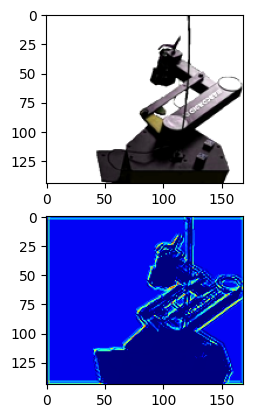

In [446]:
def make_gradcam_heatmap(img_array, model, conv_layer, pred_index=None):
    # Create a model that maps input to the activations of the last conv layer as well as output predictions
    grad_model = tf.keras.models.Model(model.inputs, [conv_layer.output, model.output])

    # Use GradientTape to record gradients
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(np.expand_dims(img_array, axis=0))
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Compute gradients of the top class with respect to the output feature map
    grads = tape.gradient(class_channel, last_conv_layer_output)
    
    # Pool the gradients over all axes except the channel dimension
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel in the feature map by "how important this channel is" (pooled_grads)
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    print(tf.math.reduce_max(heatmap).numpy())

    # Normalize heatmap between 0 and 1
    if (tf.math.reduce_max(heatmap).numpy()==0):
        heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap)+1e-8)
    else:
        heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

from tensorflow.keras.preprocessing.image import array_to_img
last_conv2d=None
for layer in reversed(model_1.layers):
    # Check if the layer is a convolution type (Conv1D, Conv2D, or Conv3D)
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv2d=layer
        break
y_test1=np.where(y_test==1)[0]
idx=np.random.randint(0,len(y_test1))
img = x_test[y_test1[idx]]

heatmap = make_gradcam_heatmap(img, model_1, last_conv2d)

       
# Rescale heatmap and apply color

heatmap = np.uint8(255 * heatmap)
jet = plt.get_cmap("jet")
jet_colors = jet(np.arange(256))[:, :3]
jet_heatmap = jet_colors[heatmap]

# Resize and superimpose
jet_heatmap = array_to_img(jet_heatmap).resize((img.shape[1], img.shape[0]))
jet_heatmap = img_to_array(jet_heatmap)
superimposed_img = jet_heatmap * 0.4 + img
superimposed_img = array_to_img(superimposed_img)

# Display result
plt.subplot(2, 1, 1)
plt.imshow(img)
if (np.all(heatmap == 0) or np.isnan(heatmap).all()):
        raise RuntimeError("training instability")
plt.subplot(2, 1, 2)
plt.imshow(superimposed_img)
plt.show()

/home/kerry/.local/lib/python3.7/site-packages/sklearn/manifold/_t_sne.py:986: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  FutureWarning,


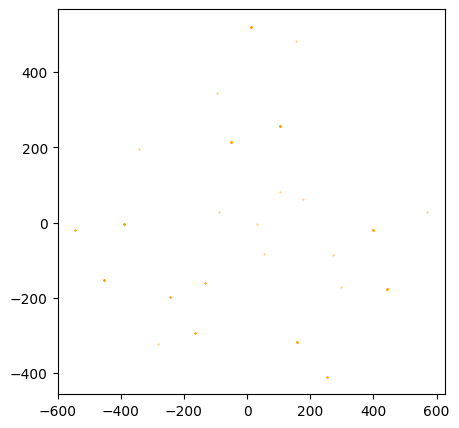

In [447]:
from sklearn.manifold import TSNE

model_feats = tf.keras.models.Model(inputs=model_1.input, outputs=model_1.layers[-3].output)
img=img_to_array(resizeImg(load_img(pref_path+'poscand2.png')))
feats=model_feats.predict(np.expand_dims(img,axis=0))
nuerLen=len(feats[0])

feats=np.repeat(feats,[len(y_test1)])
if len(feats.shape) > 2:
    feats = feats.reshape(feats.shape[0], -1)
elif len(feats.shape) == 1:
    feats = feats.reshape(len(y_test1), nuerLen)
# Initialize t-SNE to output 2 components (X and Y coordinates)
tsne = TSNE(n_components=2, 
    perplexity=30.0,      # Balance local vs global data structure (usually 5-50)
    learning_rate='auto', # Standard step size setting
    init='pca',           # Highly recommended for stability and speed
    random_state=52       # Ensures reproducibility
).fit_transform(feats)

plt.figure(figsize=(5, 5))


# Overlay the coordinate points
# 'ro' makes the markers red circles; 'ms' sets the marker size
plt.scatter(tsne[:, 0], tsne[:, 1], color='orange', marker='o', s=0.1, label='Target Pixels')
plt.show()

In [448]:
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'01mod.png'))),axis=0)))
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'poscand.png'))),axis=0)))
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'poscand1.png'))),axis=0)))
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'poscand2.png'))),axis=0)))
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'negcand.png'))),axis=0)))
print (model_1.predict(np.expand_dims(img_to_array(resizeImg(load_img(pref_path+'negcand2.png'))),axis=0)))

[[0.98094183]]
[[0.98092663]]
[[0.98059285]]
[[0.86758447]]
[[0.02976096]]
[[0.35290316]]


In [449]:
# to save memory
del x_train
del y_train
del x_test
del y_test1

import gc
gc.collect()

774157

In [450]:
class SiameseModel(tf.keras.Model):
    """The Siamese Network model with a custom training and testing loops.

    Computes the triplet loss using the three embeddings produced by the
    Siamese Network.

    The triplet loss is defined as:
       L(A, P, N) = max(‖f(A) - f(P)‖² - ‖f(A) - f(N)‖² + margin, 0)
    """

    def __init__(self, siamese_network, margin=0.5):
        super().__init__()
        self.siamese_network = siamese_network
        self.margin = margin
        self.loss_tracker =  tf.keras.metrics.Mean(name="loss")
        self.valloss_tracker=tf.keras.metrics.Mean(name="val_loss")

    def call(self, inputs):
        return self.siamese_network(inputs)
    def train_step(self, inputs):
        # GradientTape is a context manager that records every operation that
        # you do inside. We are using it here to compute the loss so we can get
        # the gradients and apply them using the optimizer specified in
        # `compile
        #inputs=tf.unstack(inputs, axis=1)
        with tf.GradientTape() as tape:
            # compute the distance between the anchor and positive,
            # negative images
            (apDistance, anDistance) = self._compute_distance(inputs)
            # calculate the loss of the siamese network
            loss = self._compute_loss(apDistance, anDistance)

        # Storing the gradients of the loss function with respect to the
        # weights/parameters.
        gradients = tape.gradient(loss, self.siamese_network.trainable_weights)

        # Applying the gradients on the model using the specified optimizer
        self.optimizer.apply_gradients(
            zip(gradients, self.siamese_network.trainable_weights)
        )

        # Let's update and return the training loss metric.
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}
    
    def test_step(self, inputs):
        # compute the distance between the anchor and positive,
        # negative images
        (apDistance, anDistance) = self._compute_distance(inputs)
        # calculate the loss of the siamese network
        loss = self._compute_loss(apDistance, anDistance)
        
        # update the metrics and return the loss
        self.valloss_tracker.update_state(loss)
        return {"loss": self.valloss_tracker.result()}
    def verify (self,ancinp,posinp):
        embeddings = self.siamese_network((ancinp, posinp, posinp))
        return (np.linalg.norm(tf.subtract(embeddings[1],embeddings[0]),ord=2),tf.keras.metrics.CosineSimilarity()(
            embeddings[0],embeddings[1]))
    
    def _compute_distance(self, inputs):
        (anchor, positive, negative) = inputs[0]
        # embed the images using the siamese network
        embeddings = self.siamese_network((anchor, positive, negative))
        anchorEmbedding = embeddings[0]
        positiveEmbedding = embeddings[1]
        negativeEmbedding = embeddings[2]
        # calculate the anchor to positive and negative distance
        apDistance = tf.reduce_sum(
            tf.square(anchorEmbedding - positiveEmbedding), axis=-1
        )
        anDistance = tf.reduce_sum(
            tf.square(anchorEmbedding - negativeEmbedding), axis=-1
        )
        
        # return the distances
        return (apDistance, anDistance)
    def _compute_loss(self, apDistance, anDistance):
        loss = apDistance - anDistance
        loss = tf.maximum(loss + self.margin, 0.0)
        return loss
  
    @property
    def metrics(self):
        # We need to list our metrics here so the `reset_states()` can be
        # called automatically.
        return [self.loss_tracker]



In [456]:
inp_anc=tf.keras.layers.Input(shape=input_shape)
inp_pos=tf.keras.layers.Input(shape=input_shape)
inp_neg=tf.keras.layers.Input(shape=input_shape)
inner_model = tf.keras.Sequential()
for layer in model_1.layers[0:-6]:
    inner_model.add(layer)
    layer.trainable = False
#add another convolution layer to learn patterns that differentiate positive from negative    
inner_model.add(Conv2D(4, (2, 2), padding='valid'))
inner_model.add(tf.keras.layers.BatchNormalization())
inner_model.add(Activation('tanh'))
inner_model.add(Flatten())
inner_model.add(Dense(model_1.layers[-5].units-2))
inner_model.add(model_1.layers[-4])
inner_model.add(model_1.layers[-3])
emb_anc = inner_model(inp_anc)
emb_pos = inner_model(inp_pos)
emb_neg = inner_model(inp_neg)

siamese_net=tf.keras.Model(inputs=[inp_anc, inp_pos, inp_neg],
                             outputs=[emb_anc, emb_pos, emb_neg])
siamese_net.summary()
siamese_model=SiameseModel(siamese_net)

siamese_model.compile(optimizer='adam')
callbacks=[tf.keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.3, patience=3),
          StopAtLossValue(target_loss=0.05)]


Model: "functional_251"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_122 (InputLayer)          [(None, 144, 169, 3) 0                                            
__________________________________________________________________________________________________
input_123 (InputLayer)          [(None, 144, 169, 3) 0                                            
__________________________________________________________________________________________________
input_124 (InputLayer)          [(None, 144, 169, 3) 0                                            
__________________________________________________________________________________________________
sequential_98 (Sequential)      (None, 7)            75278       input_122[0][0]                  
                                                                 input_123[0][0]     

In [452]:
#from pathlib import Path
import math

def est_noise_lvl(rgb_img):
    # Laplacian kernel for noise estimate
    # Convolve image with Laplacian kernel
    # Calculate absolute sum
    # Estimate sigma (noise level)
    h, w,_ = rgb_img.shape
    return (np.sum(np.abs(cv2.filter2D(cv2.cvtColor(rgb_img.astype(np.float32),\
        cv2.COLOR_RGB2GRAY).astype(np.float64), -1,\
        np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]]))))* math.sqrt(\
        0.5 * math.pi) / (6 * (w - 2) * (h - 2)))

datagenScal = ImageDataGenerator(
    rotation_range=5,
    shear_range=0.5,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
)
# set anchor to positive images
anc=possmp
possmp=np.empty((0,possmp.shape[1],possmp.shape[2],possmp.shape[3]))
# set positive anchor to images a shade off anchor-removing noise
for k in range(len(anc)):
    if (est_noise_lvl(anc[k]) > 0.05):
        r, g, b = cv2.split((anc[k]*255).astype(np.uint8))
        possmp=np.append(possmp,np.expand_dims(datagenScal.random_transform(np.dstack((\
           cv2.fastNlMeansDenoising(cv2.morphologyEx(cv2.morphologyEx(r,cv2.MORPH_CLOSE, (7,7)),cv2.MORPH_OPEN,\
           (7,7)),None,10,7,21),cv2.fastNlMeansDenoising(cv2.morphologyEx(cv2.morphologyEx(g,cv2.MORPH_CLOSE, (7,7)),\
           cv2.MORPH_OPEN,(7,7)),None,10,7,21),cv2.fastNlMeansDenoising(cv2.morphologyEx(cv2.morphologyEx(\
           b,cv2.MORPH_CLOSE,(7,7)),cv2.MORPH_OPEN,(7,7)),None,10,7,21)))).astype(np.float32)/255,axis=0),axis=0)
    else:
        possmp=np.append(possmp,np.expand_dims(datagenScal.random_transform(anc[k]),axis=0),axis=0)    


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


anchor image set


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

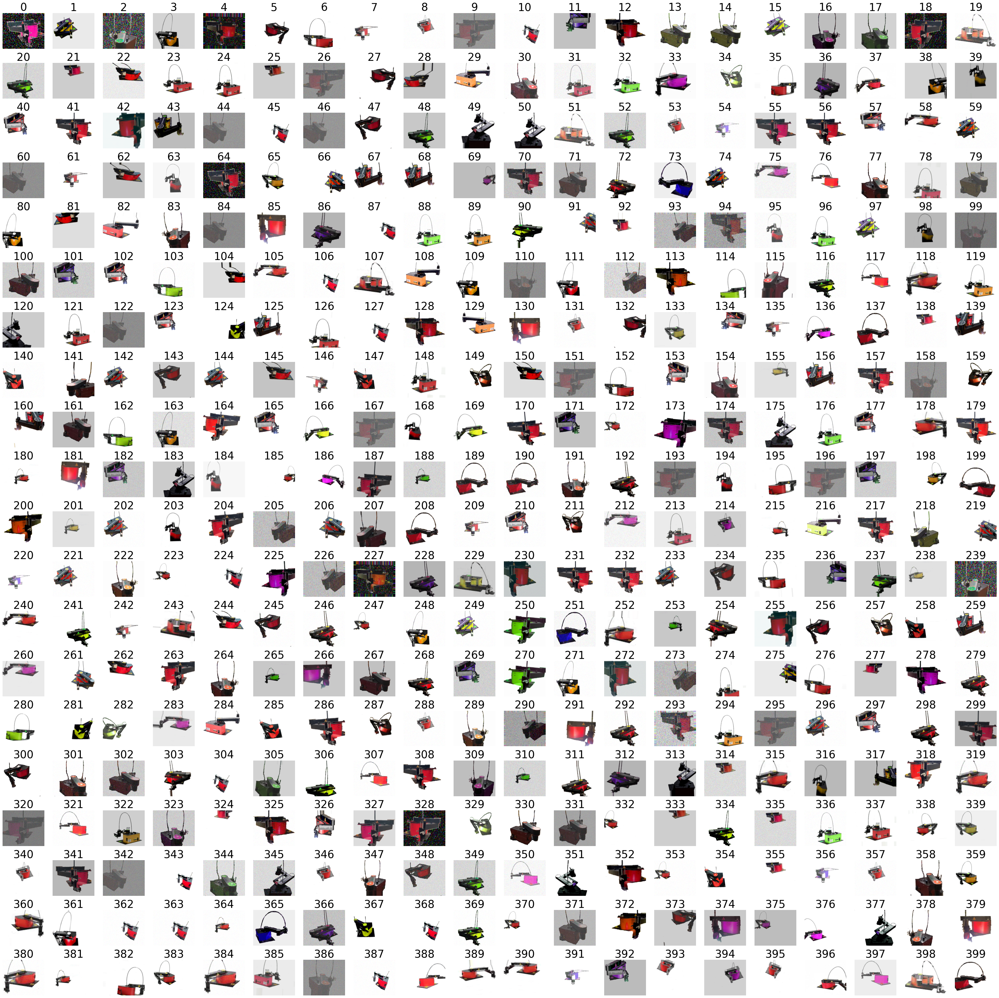

positive image set


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

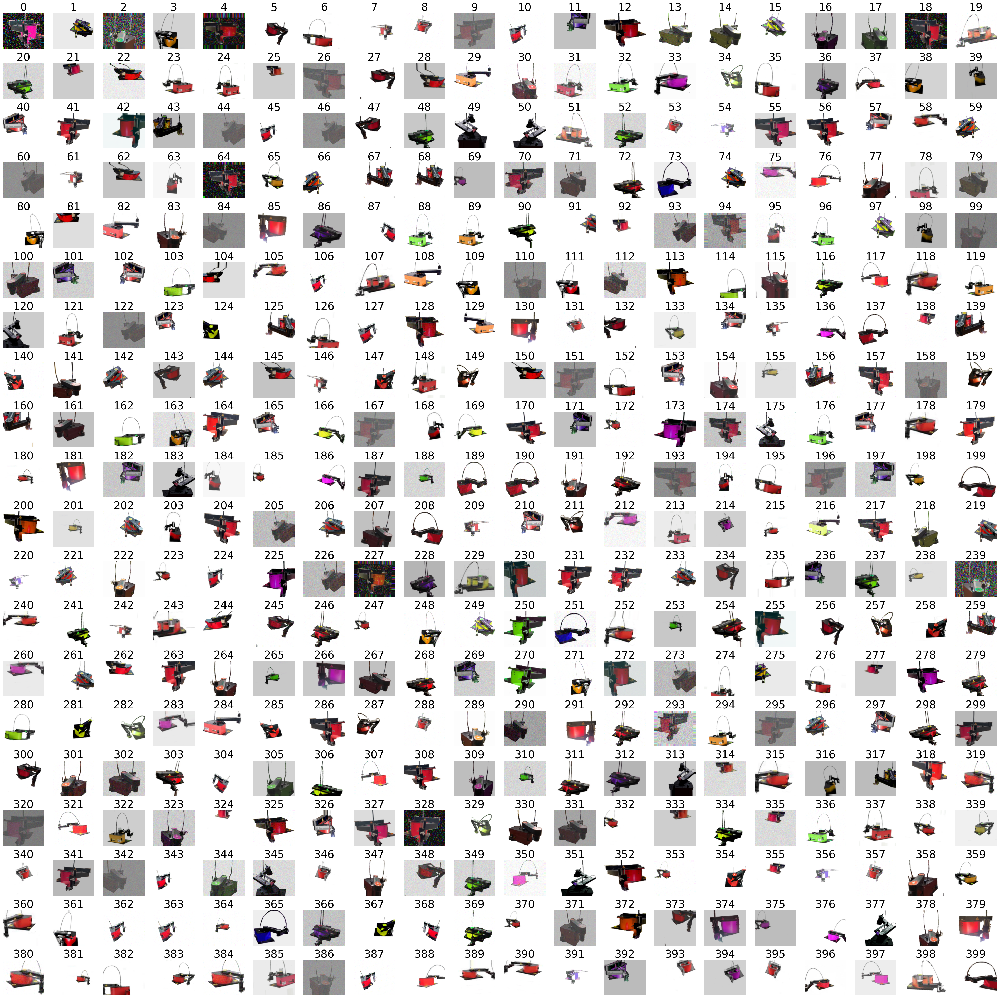

In [275]:
print('anchor image set')
plt.figure(figsize=(50, 50))
for i in range(0,len(anc)):
    plt.subplot(20, 20, i+1)
    plt.title(i, fontsize=30)
    plt.imshow(anc[i])
    plt.axis('off')
plt.show()
print('positive image set')
plt.figure(figsize=(50, 50))
for i in range(0,len(possmp)):
    plt.subplot(20, 20, i+1)
    plt.title(i, fontsize=30)
    plt.imshow(possmp[i])
    plt.axis('off')
plt.show()

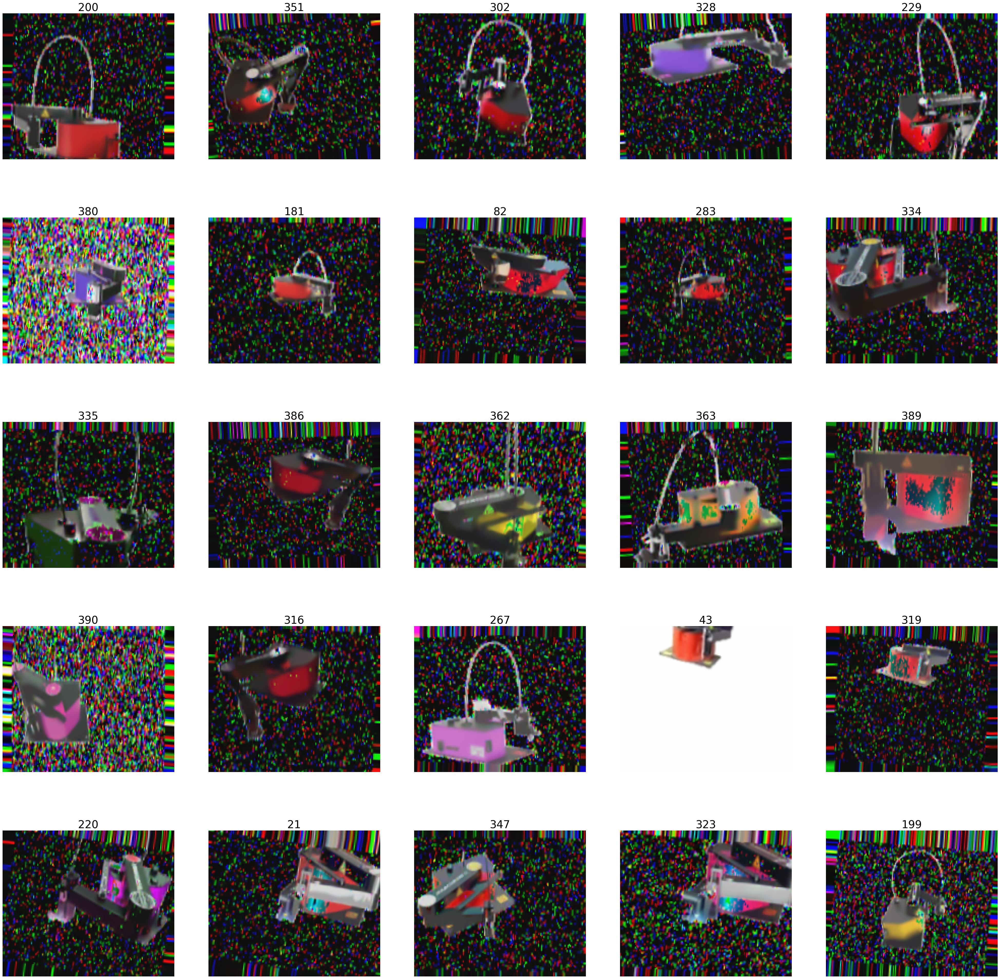

In [27]:
y=model_1.predict(possmp)

plt.figure(figsize=(50, 50))
for i in [i for i, val in enumerate(y) if val < 0.5]:
    plt.subplot(5, 5, (i%25)+1)
    plt.title(i,fontsize=30)
    plt.imshow(possmp[i])
#    if not Path("falsneg"+str(i)+".png").exists():
#        save_img("falsneg"+str(i)+".png",anc[i])
    plt.axis('off')
plt.show()

#print (rf_grid.predict(np.expand_dims(get_features_rfc(img_to_array(resizeImg(load_img(pref_path+'01mod.png'))))[imp_idxs],axis=0)))
del y

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


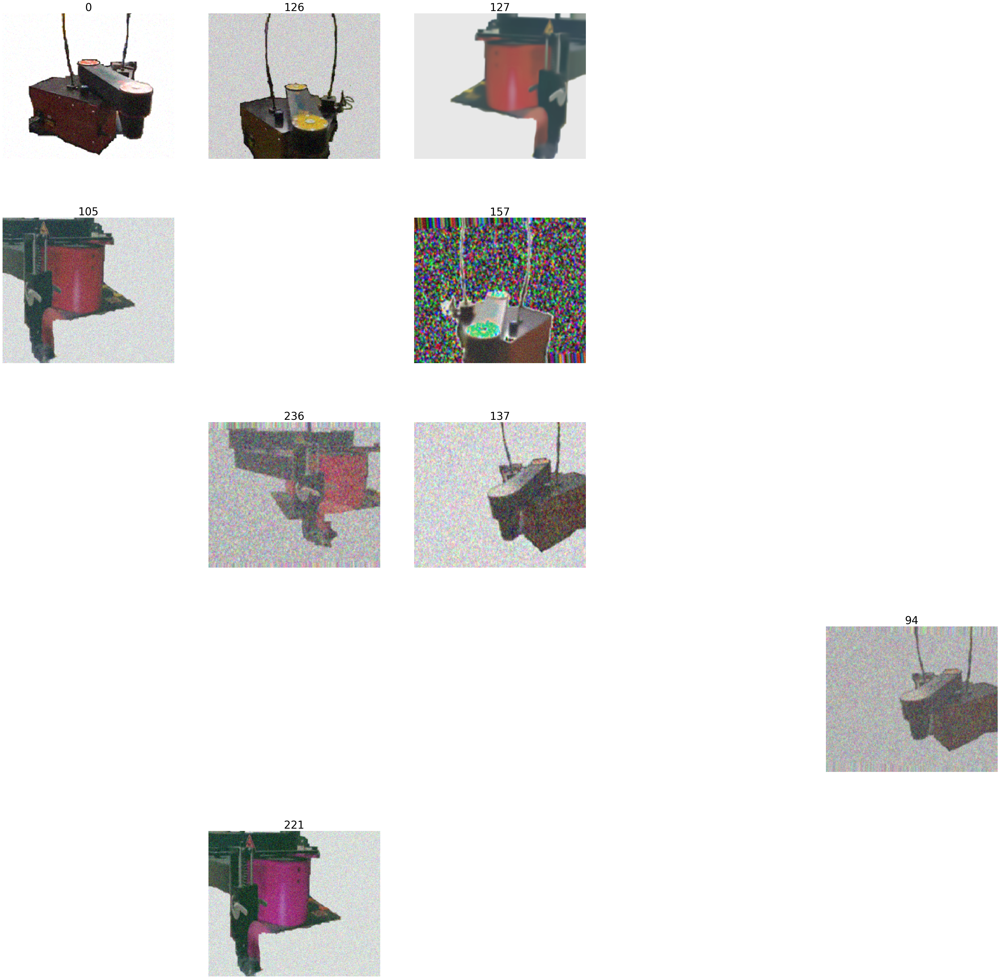

In [515]:
rfc_feats=np.zeros((0,200000,))
for img in possmp:
    rfc_feats=np.concatenate((rfc_feats,np.expand_dims(get_features_rfc(img)[imp_idxs],axis=0)),axis=0)
y=rf_grid.predict(rfc_feats)
plt.figure(figsize=(50, 50))
for i in [i for i, val in enumerate(y) if val < 0.5]:
    plt.subplot(5, 5, (i%25)+1)
    plt.title(i,fontsize=30)
    plt.imshow(anc[i])
#    if not Path("falsneg"+str(i)+".png").exists():
#        save_img("falsneg"+str(i)+".png",anc[i])
    plt.axis('off')
plt.show()
del y
del rfc_feats

In [416]:
def resizeImg(img):
    return img.resize((img.width * scal, img.height * scal))
"""tf.keras.preprocessing.image.save_img('10clip6.png',resizeImg(array_to_img(anc[211])),scale=True)
tf.keras.preprocessing.image.save_img('10clip7.png',resizeImg(array_to_img(anc[121])),scale=True)"""
tf.keras.preprocessing.image.save_img('10clip8.png',resizeImg(array_to_img(anc[49])),scale=True)
tf.keras.preprocessing.image.save_img('10clip9.png',resizeImg(array_to_img(anc[120])),scale=True)
tf.keras.preprocessing.image.save_img('10clip10.png',resizeImg(array_to_img(anc[39])),scale=True)
"""tf.keras.preprocessing.image.save_img('falsneg248.png',resizeImg(array_to_img(anc[147])),scale=True)
tf.keras.preprocessing.image.save_img('falsneg249.png',resizeImg(array_to_img(anc[73])),scale=True)
tf.keras.preprocessing.image.save_img('falsneg250.png',resizeImg(array_to_img(anc[115])),scale=True)
tf.keras.preprocessing.image.save_img('falsneg251.png',resizeImg(array_to_img(anc[6])),scale=True)
tf.keras.preprocessing.image.save_img('falsneg252.png',resizeImg(array_to_img(anc[2])),scale=True)"""

"tf.keras.preprocessing.image.save_img('falsneg248.png',resizeImg(array_to_img(anc[147])),scale=True)\ntf.keras.preprocessing.image.save_img('falsneg249.png',resizeImg(array_to_img(anc[73])),scale=True)\ntf.keras.preprocessing.image.save_img('falsneg250.png',resizeImg(array_to_img(anc[115])),scale=True)\ntf.keras.preprocessing.image.save_img('falsneg251.png',resizeImg(array_to_img(anc[6])),scale=True)\ntf.keras.preprocessing.image.save_img('falsneg252.png',resizeImg(array_to_img(anc[2])),scale=True)"

In [457]:
np.random.RandomState(seed=32).shuffle(negsmp)
anc_train,anc_test=train_test_split(anc, test_size=0.2, random_state=42)
pos_train,pos_test=train_test_split(possmp, test_size=0.2, random_state=42)
neg_train,neg_test=train_test_split(negsmp, test_size=0.2, random_state=42)

    
history=siamese_model.fit(x=[anc_train,pos_train,neg_train], batch_size=batch_size,epochs=100,
                          callbacks=callbacks,validation_data=[anc_test,pos_test,neg_test])
loss=min(history.history['loss'])
val_loss = history.history['val_loss']

# View the final epoch's validation loss:

print(f"Final validation loss: {val_loss[-1]}")
print ('loss:'+str(loss))


Epoch 1/100
32/32 [==============================] - 4s 139ms/step - loss: 0.1584 - val_loss: 0.1331
Epoch 2/100
32/32 [==============================] - 4s 140ms/step - loss: 0.1156 - val_loss: 0.1498
Epoch 3/100
32/32 [==============================] - 5s 141ms/step - loss: 0.0703 - val_loss: 0.1252
Epoch 4/100
32/32 [==============================] - 4s 138ms/step - loss: 0.0511 - val_loss: 0.1305
Epoch 5/100
32/32 [==============================] - 5s 152ms/step - loss: 0.0420 - val_loss: 0.1202
Epoch 6/100
32/32 [==============================] - 4s 137ms/step - loss: 0.0204 - val_loss: 0.1064
Epoch 7/100
32/32 [==============================] - 4s 139ms/step - loss: 0.0219 - val_loss: 0.0966
Epoch 8/100
32/32 [==============================] - 4s 137ms/step - loss: 0.0219 - val_loss: 0.0892
Epoch 9/100
32/32 [==============================] - 4s 138ms/step - loss: 0.0218 - val_loss: 0.0835
Epoch 10/100
32/32 [==============================] - 5s 145ms/step - loss: 0.0218 - val_lo

In [458]:
print(siamese_model.verify(np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('01mod.png'))) / 255.0, axis=0),
                           np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('poscand1.png'))) / 255.0, axis=0)))
print(siamese_model.verify(np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('01mod.png'))) / 255.0, axis=0),
                           np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('falspos0.png'))) / 255.0, axis=0)))
print(siamese_model.verify(np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('03mod.png'))) / 255.0, axis=0),
                           np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('poscand2.png'))) / 255.0, axis=0)))
print(siamese_model.verify(np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('03mod.png'))) / 255.0, axis=0),
                           np.expand_dims(np.array(resizeImg(tf.keras.preprocessing.image.load_img('negcand2.png'))) / 255.0, axis=0)))
del anc_train,anc_test,pos_train,pos_test,neg_train,neg_test
import gc
gc.collect()

(0.0, <tf.Tensor: shape=(), dtype=float32, numpy=1.0000002>)
(5.2792015, <tf.Tensor: shape=(), dtype=float32, numpy=-0.9999336>)
(0.0, <tf.Tensor: shape=(), dtype=float32, numpy=1.0000002>)
(2.1941695, <tf.Tensor: shape=(), dtype=float32, numpy=0.60946786>)


8680